# Credit Scoring Model

## 1. Import Libraries and Load Data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, RocCurveDisplay, ConfusionMatrixDisplay, classification_report

DATA_PATH = Path('data.csv')
TARGET = 'Loan_Approved'
SEED = 42

if not DATA_PATH.exists():
    raise FileNotFoundError(f'Dataset not found: {DATA_PATH}')

df = pd.read_csv(DATA_PATH)
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


## 2. Inspect and Prepare the Dataset

In [2]:
print(f'Shape: {df.shape}')
display(df.info())
display(df.isna().sum().sort_values(ascending=False).to_frame('Missing values'))
display(df[TARGET].value_counts(normalize=True).rename('Proportion'))

Shape: (1000, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-null    ob

None

,Missing values
Applicant_ID,50
Applicant_Income,50
Employer_Category,50
Gender,50
Education_Level,50
Property_Area,50
Loan_Purpose,50
Loan_Term,50
Loan_Amount,50
Collateral_Value,50


Loan_Approved
No     0.686316
Yes    0.313684
Name: Proportion, dtype: float64

## 3. Feature Engineering

In [3]:
df = df.dropna(subset=[TARGET]).copy()
# Rows without an approval outcome cannot be used for supervised learning
features = df.drop(columns=[TARGET, 'Applicant_ID'], errors='ignore').copy()
target = LabelEncoder().fit_transform(df[TARGET])

# Financial ratios give the models meaningful affordability signals
features['Total_Income'] = features['Applicant_Income'] + features['Coapplicant_Income']
features['Loan_to_Income'] = features['Loan_Amount'] / features['Total_Income'].replace(0, np.nan)
features['Collateral_Coverage'] = features['Collateral_Value'] / features['Loan_Amount'].replace(0, np.nan)
features['Income_per_Dependent'] = features['Total_Income'] / (features['Dependents'].fillna(0) + 1)
features.replace([np.inf, -np.inf], np.nan, inplace=True)
features.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,...,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Total_Income,Loan_to_Income,Collateral_Coverage,Income_per_Dependent
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,...,84.0,Personal,Urban,Not Graduate,Female,Private,19182.0,0.866385,2.746134,19182.000000
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,...,NaN,Car,Semiurban,Graduate,NaN,Private,5539.0,6.984474,1.273606,1384.750000
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,...,72.0,NaN,Urban,NaN,Female,Government,9496.0,2.942607,0.247218,3165.333333
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,...,60.0,Business,Rural,Graduate,Female,Government,22137.0,1.256674,0.389806,7379.000000
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,...,72.0,Car,NaN,Graduate,Male,Private,17507.0,0.727766,2.953379,5835.666667


## 4. Split Data and Build the Preprocessing Pipeline

In [4]:
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.20, stratify=target, random_state=SEED)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
categorical_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))])
preprocessor = ColumnTransformer([('numeric', numeric_pipeline, numeric_features), ('categorical', categorical_pipeline, categorical_features)])
print(f'Training rows: {len(X_train)} | Test rows: {len(X_test)}')

Training rows: 760 | Test rows: 190


## 5. Train Classification Models

In [5]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight='balanced', random_state=SEED, n_jobs=-1)
}

fitted_models, results = {}, []
for name, classifier in models.items():
    pipeline = Pipeline([('preprocessor', preprocessor), ('classifier', classifier)])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    fitted_models[name] = pipeline
    results.append({'Model': name, 'Accuracy': accuracy_score(y_test, predictions), 'Precision': precision_score(y_test, predictions, average='weighted', zero_division=0), 'Recall': recall_score(y_test, predictions, average='weighted', zero_division=0), 'F1-score': f1_score(y_test, predictions, average='weighted', zero_division=0), 'ROC-AUC': roc_auc_score(y_test, probabilities)})

results = pd.DataFrame(results).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
results

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest,0.957895,0.959534,0.957895,0.958245,0.980128
1,Logistic Regression,0.847368,0.859298,0.847368,0.850405,0.927692


## 6. Evaluate the Best Model

Best model: Random Forest
              precision    recall  f1-score   support

Not Approved       0.98      0.95      0.97       130
    Approved       0.91      0.97      0.94        60

    accuracy                           0.96       190
   macro avg       0.95      0.96      0.95       190
weighted avg       0.96      0.96      0.96       190



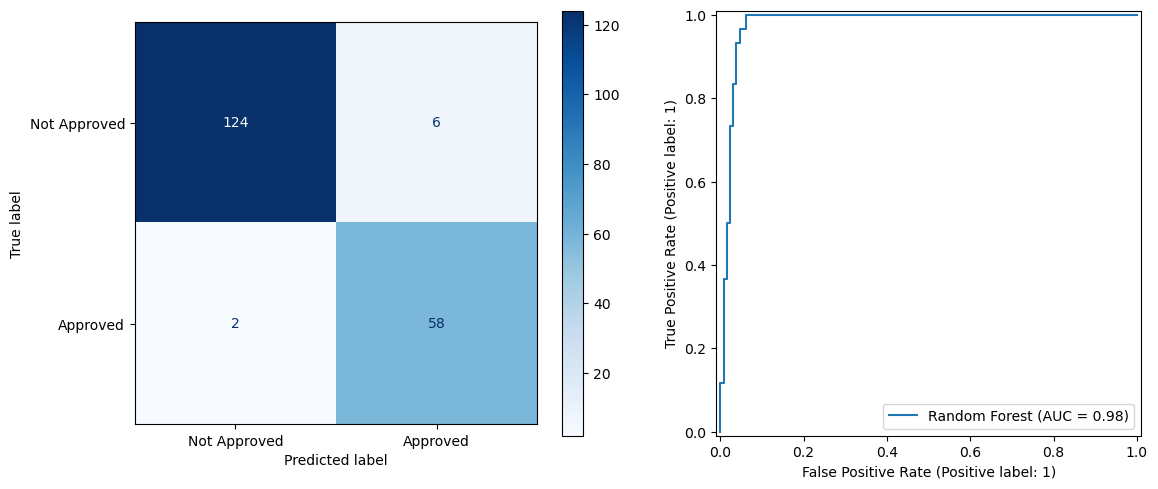

In [6]:
best_name = results.loc[0, 'Model']
best_model = fitted_models[best_name]
best_predictions = best_model.predict(X_test)
best_probabilities = best_model.predict_proba(X_test)[:, 1]
print(f'Best model: {best_name}')
print(classification_report(y_test, best_predictions, target_names=['Not Approved', 'Approved']))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, best_predictions, display_labels=['Not Approved', 'Approved'], cmap='Blues', ax=axes[0])
RocCurveDisplay.from_predictions(y_test, best_probabilities, name=best_name, ax=axes[1])
plt.tight_layout()
plt.show()

## 7. View Important Features

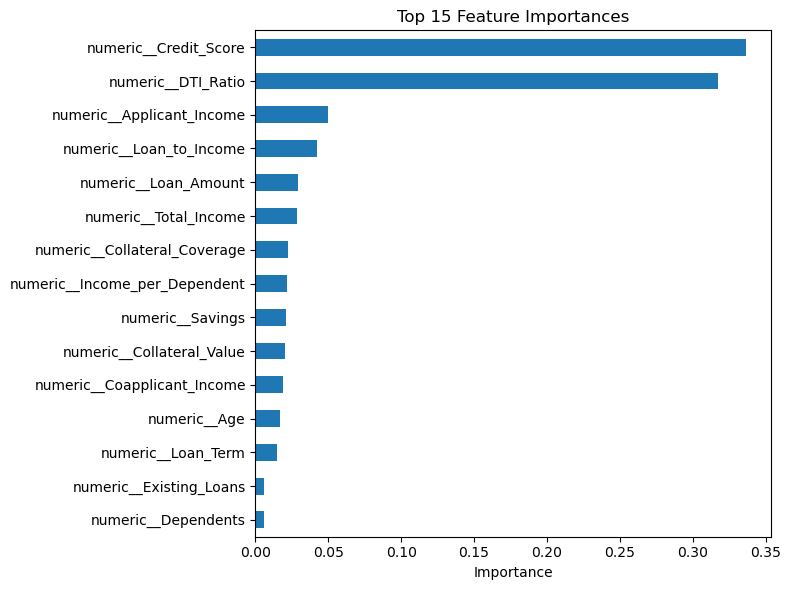

In [7]:
if best_name == 'Random Forest':
    feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()
    importance = pd.Series(best_model.named_steps['classifier'].feature_importances_, index=feature_names).sort_values(ascending=False).head(15)
    importance.sort_values().plot.barh(figsize=(8, 6), title='Top 15 Feature Importances')
    plt.xlabel('Importance')
    plt.tight_layout()
    plt.show()
else:
    print('Random Forest was not the best model; feature importances are not displayed.')